In [64]:
# CNN Image Classification: Rock, Paper, Scissors

## 1. Import Libraries
from torchvision import datasets
import torchvision.transforms as transforms

from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)


cpu


In [65]:
## 2. Load and Explore Dataset
import kagglehub
import os

path = kagglehub.dataset_download(
    "frtgnn/rock-paper-scissor"
)

print(path)
print(os.listdir(path))

Using Colab cache for faster access to the 'rock-paper-scissor' dataset.
/kaggle/input/rock-paper-scissor
['rps-test-set', 'rps']


In [66]:
### Dataset Exploration
print("Classes:", train_data.classes)
print("Number of Training Images:", len(train_data))
print("Number of Validation Images:", len(val_data))
print("Number of Test Images:", len(test_data))

Classes: ['paper', 'rock', 'scissors']
Number of Training Images: 2520
Number of Validation Images: 186
Number of Test Images: 186


In [67]:
## 3. Data Preprocessing and Augmentation
import torchvision.transforms as transforms
from torch.utils.data import random_split

size = 32
train_transform = transforms.Compose([
    transforms.Resize((size, size)),        # resize to model input size
    transforms.RandomHorizontalFlip(),    # horizontal flip augmentation
    transforms.RandomRotation(15),        # rotate ±15 degrees
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()                # convert PIL → float tensor [0.0,1.0]
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

train_folder = path+'/rps/rps'
test_folder = path+'/rps-test-set/rps-test-set'

train_data = datasets.ImageFolder(train_folder, transform = train_transform)
val_test_data = datasets.ImageFolder(test_folder,transform = val_transform)

# Split original test dataset into validation (50%) and test (50%)
val_size = len(val_test_data) // 2
test_size = len(val_test_data) - val_size

val_data, test_data = random_split(
    val_test_data,
    [val_size, test_size]
)

In [68]:
### Hyperparameters
batch_size = 32
learning_rate=1e-3
epoch_number = 10

In [69]:
#Data Loaders
trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

In [70]:
##  Define CNN Architecture
from torch.optim import SGD, Adam
def get_model():
    model = nn.Sequential(
        #Feature Extraction
        nn.Conv2d(3, 64, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 128, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),

        #Classifier
        nn.Flatten(),
        nn.Linear(128*6*6, 256),
        nn.ReLU(),
        nn.Linear(256, 3)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

In [71]:
##  Training Loop with Validation
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)   # move to device here
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [72]:
from torchsummary import summary
model, loss_fn, optimizer = get_model()
summary(model, input_size=(3,32,32));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 30, 30]           1,792
              ReLU-2           [-1, 64, 30, 30]               0
         MaxPool2d-3           [-1, 64, 15, 15]               0
            Conv2d-4          [-1, 128, 13, 13]          73,856
              ReLU-5          [-1, 128, 13, 13]               0
         MaxPool2d-6            [-1, 128, 6, 6]               0
           Flatten-7                 [-1, 4608]               0
            Linear-8                  [-1, 256]       1,179,904
              ReLU-9                  [-1, 256]               0
           Linear-10                    [-1, 3]             771
Total params: 1,256,323
Trainable params: 1,256,323
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 1.39
Params size (MB): 4.79
Estimat

In [73]:
## Training Loop ###
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):
  epoch_loss, epoch_accuracy = train_one_epoch(trn_dl,model,loss_fn,optimizer)
  train_losses.append(epoch_loss)
  train_accuracies.append(epoch_accuracy)

  v_loss, v_acc =  validation(val_dl,model,loss_fn)
  val_losses.append(v_loss)
  val_accuracies.append(v_acc)

  print(f"Epoch [{epoch + 1}/{epoch_number}]"
        f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
        f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

Epoch [1/10] | Train Loss: 0.8386 | Train Accuracy: 62.02% | Val Loss: 0.6392 | Val Accuracy: 74.19%
Epoch [2/10] | Train Loss: 0.2202 | Train Accuracy: 92.62% | Val Loss: 0.4162 | Val Accuracy: 79.57%
Epoch [3/10] | Train Loss: 0.0826 | Train Accuracy: 97.98% | Val Loss: 0.2354 | Val Accuracy: 85.48%
Epoch [4/10] | Train Loss: 0.0546 | Train Accuracy: 98.45% | Val Loss: 0.1541 | Val Accuracy: 94.62%
Epoch [5/10] | Train Loss: 0.0371 | Train Accuracy: 99.05% | Val Loss: 0.3423 | Val Accuracy: 80.65%
Epoch [6/10] | Train Loss: 0.0358 | Train Accuracy: 98.77% | Val Loss: 0.2597 | Val Accuracy: 90.86%
Epoch [7/10] | Train Loss: 0.0223 | Train Accuracy: 99.48% | Val Loss: 0.2450 | Val Accuracy: 92.47%
Epoch [8/10] | Train Loss: 0.0093 | Train Accuracy: 99.76% | Val Loss: 0.4107 | Val Accuracy: 80.11%
Epoch [9/10] | Train Loss: 0.0212 | Train Accuracy: 99.25% | Val Loss: 0.1250 | Val Accuracy: 94.09%
Epoch [10/10] | Train Loss: 0.0147 | Train Accuracy: 99.56% | Val Loss: 0.0867 | Val Accura

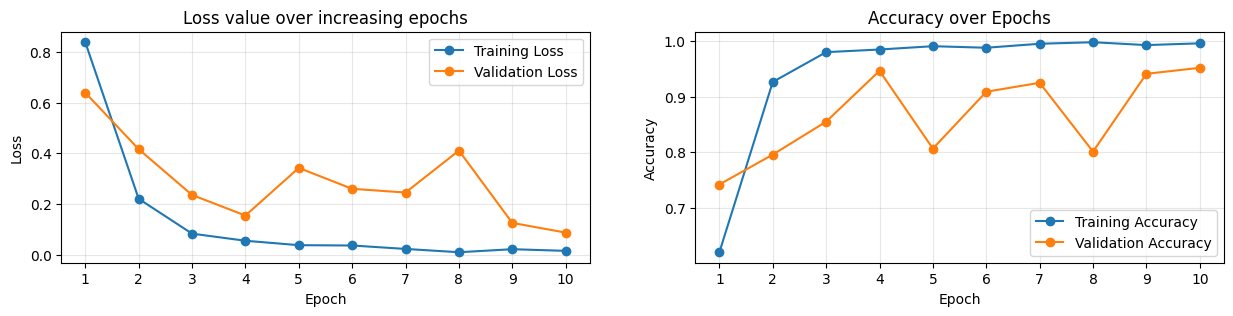

In [74]:
##  Visualizations (Loss and Accuracy Curves)
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 3))
plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [75]:
# Evaluate Model on Test Set
@torch.no_grad()
def test_model(data_loader, model, loss_fn):
    model.eval()

    test_losses, test_accuracies = [], []

    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        prediction = model(x)

        test_losses.append(loss_fn(prediction, y).item())

        is_correct = (prediction.argmax(-1) == y).tolist()
        test_accuracies.extend(is_correct)

    return np.mean(test_losses), np.mean(test_accuracies)


test_loss, test_acc = test_model(test_dl, model, loss_fn)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

Test Loss: 0.0925
Test Accuracy: 97.85%


In [76]:
from sklearn.metrics import confusion_matrix

all_predictions, all_labels = [], []

model.eval()

with torch.no_grad():
    for x, y in test_dl:
        x = x.to(device)

        prediction = model(x)
        predicted_labels = prediction.argmax(-1)

        all_predictions.extend(predicted_labels.cpu().tolist())
        all_labels.extend(y.tolist())

cm = confusion_matrix(all_labels, all_predictions)

print("Confusion Matrix:")
print(cm)



Confusion Matrix:
[[65  0  0]
 [ 0 57  0]
 [ 4  0 60]]


In [77]:
torch.save(model.state_dict(), "CNN_51148.pth")
print("Model saved!")

Model saved!


In [78]:
"""### 8. Analysis and Discussion
### Explanation of Curves
- **Training:** Training loss dropped from 0.6627 to 0.0124 and training accuracy rose from 71.83% to 99.60%. The model learned the training data very well.
- **Validation:** Validation accuracy improved from 71.51% to a best of 98.39% (epoch 5), and the final epoch reached 97.31% with a validation loss of 0.0995.
- **Fluctuation:** Validation accuracy dropped in epochs 7 and 8 (88.71% and 87.10%) and then recovered. This is probably because of the high learning rate (1e-3) and the small validation set, where a few images change the accuracy noticeably.
- **Overfitting:** The gap between training (99.60%) and validation (97.31%) is small, so there is only mild overfitting. Training loss keeps falling while validation loss stops improving after epoch 5, which is a sign of slight overfitting.
- The model achieved **92.47% test accuracy** with a test loss of **0.2908** on 186 unseen images.
"""

'### 8. Analysis and Discussion\n### Explanation of Curves\n- **Training:** Training loss dropped from 0.6627 to 0.0124 and training accuracy rose from 71.83% to 99.60%. The model learned the training data very well.\n- **Validation:** Validation accuracy improved from 71.51% to a best of 98.39% (epoch 5), and the final epoch reached 97.31% with a validation loss of 0.0995.\n- **Fluctuation:** Validation accuracy dropped in epochs 7 and 8 (88.71% and 87.10%) and then recovered. This is probably because of the high learning rate (1e-3) and the small validation set, where a few images change the accuracy noticeably.\n- **Overfitting:** The gap between training (99.60%) and validation (97.31%) is small, so there is only mild overfitting. Training loss keeps falling while validation loss stops improving after epoch 5, which is a sign of slight overfitting.\n- The model achieved **92.47% test accuracy** with a test loss of **0.2908** on 186 unseen images.\n'

In [80]:
"""## 9. Conclusions and Future Work
**Conclusion:** A custom CNN was trained on the Rock-Paper-Scissors dataset and reached **92.47% test accuracy**. The Adam optimizer and data augmentation worked well for this task. The main error was rock being predicted as scissors.

**Future work:**
- Add BatchNorm and Dropout to reduce overfitting
- Use larger images (64x64 or 128x128) to keep finger details
- Try transfer learning (ResNet, MobileNet)
- Train for more epochs with a learning rate scheduler"""

'## 9. Conclusions and Future Work\n**Conclusion:** A custom CNN was trained on the Rock-Paper-Scissors dataset and reached **92.47% test accuracy**. The Adam optimizer and data augmentation worked well for this task. The main error was rock being predicted as scissors.\n\n**Future work:**\n- Add BatchNorm and Dropout to reduce overfitting\n- Use larger images (64x64 or 128x128) to keep finger details\n- Try transfer learning (ResNet, MobileNet)\n- Train for more epochs with a learning rate scheduler'